# 04 RESIRE による再構成 / Reconstruction with RESIRE

**RESIRE**（REal Space Iterative REconstruction）は，実空間で反復する再構成法です（Pham *et al.*, *Sci. Rep.* **13**, 5624 (2023)）．三次元像 ρ から計算した投影像 Aρ と，測定した投影像 b の差が小さくなるように

**RESIRE** (REal Space Iterative REconstruction) works in real space (Pham *et al.*, *Sci. Rep.* **13**, 5624 (2023)). It minimises the difference between the projections Aρ computed from the volume ρ and the measured projections b,

$$\min_{\rho \ge 0}\ \frac{1}{2}\,\| A\rho - b \|^2$$

を**勾配降下法**で解きます．1 回の反復は次の通りです．

by **gradient descent**. One iteration consists of:

1. 今の三次元像を投影する（Aρ） / project the current volume (Aρ);
2. 測定との差（残差）を三次元に逆投影する（Aᵀ(Aρ − b)） / back-project the residual (Aᵀ(Aρ − b));
3. その分だけ三次元像を修正し，負の値を 0 にする / update the volume and set negative values to zero.

フーリエ変換を使わず，実空間で投影と逆投影を繰り返すのが GENFIRE との違いです．`acceleration="fista"` を指定すると，FISTA（Nesterov の加速法）により少ない反復回数で収束します．

Unlike GENFIRE, no Fourier transform is used: the method alternates projection and back-projection in real space. With `acceleration="fista"`, FISTA (Nesterov acceleration) converges in fewer iterations.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # リポジトリの最上位 / repository root
sys.path.insert(0, str(ROOT / "src"))     # src/ のパッケージを使う / use the packages in src/
DATA = ROOT / "data"                      # データの保存先 / where data are saved
DATA.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100

In [2]:
import resire_cpu as rs
from scipy.ndimage import shift
from aet_tools import Particle, LiveMonitor, show_orthoslices, show_slices
INPUT = "tilt_series.npz"     # 02 で位置合わせしたデータなら / data aligned in 02: "tilt_series_aligned.npz"
d = np.load(DATA / INPUT)
projections, theta = d["projections"], d["theta"]
n, pixel_size = int(d["n"]), float(d["pixel_size"])
particle = Particle(d["positions"], d["species"], tuple(d["names"]), tuple(d["amplitudes"]), n, pixel_size)
print("projections:", projections.shape, " tilt range: %.1f to %.1f deg" % (theta.min(), theta.max()))

projections: (96, 96, 57)  tilt range: -70.0 to 70.0 deg


## 1. 回転中心をそろえる / Matching the rotation centre

再構成では，投影像のどこが**回転中心**（傾斜軸の位置）かが重要です．01 で作った投影像は，回転中心が配列の `n/2` 番目にあります（GENFIRE の約束）．一方，`resire_cpu` は `(n−1)/2` 番目を回転中心とします．そこで投影像を x, y 方向に −0.5 ピクセルずらしてから再構成します．

The position of the **rotation centre** (the tilt axis) in the projections matters. The projections from 01 have their rotation centre at index `n/2` (the GENFIRE convention), whereas `resire_cpu` uses `(n−1)/2`. We therefore shift the projections by −0.5 pixel in x and y before reconstructing.

実験データでは回転中心はわからないので，位置合わせ（アライメント）で投影像を回転中心に合わせます．回転中心が半ピクセルずれるだけでも，原子の位置の精度は下がります．

With experimental data the rotation centre is unknown, and the projections are brought onto it by alignment. Even a half-pixel error in the rotation centre degrades the precision of the atomic positions.

In [3]:
zeros = np.zeros(len(theta))
b = rs.shift_projections(projections, zeros - 0.5, zeros - 0.5)

## 2. 設定と再構成 / Settings and reconstruction

- `step_size`：1 回の修正の大きさ（標準は 2．大きすぎると発散します） / step length (default 2; too large diverges)
- `num_iterations`：反復の回数 / number of iterations
- `acceleration="fista"`：加速法．使わない場合（`"none"`）は 3 倍程度の反復が必要です． / acceleration; without it (`"none"`) about three times as many iterations are needed.

再構成中は，下の図が 5 回の反復ごとに更新されます．

While the reconstruction runs, the figure below is updated every 5 iterations.

- **R factor**：測定した投影像と，今の三次元像から計算した投影像のずれの割合 Σ|Aρ − b| / Σ|b|．反復とともに下がり，ノイズの大きさで決まる値に近づきます．
  relative mismatch Σ|Aρ − b| / Σ|b| between the measured projections and those calculated from the current volume. It decreases with iteration towards a floor set by the noise.
- **correlation with truth**：正解の三次元像との相関係数（シミュレーションでのみ計算できます）．正解は RESIRE の回転中心 `(n−1)/2` に合わせて 0.5 ピクセルずらしてあります．
  correlation coefficient with the ground truth (simulations only). The ground truth is shifted by 0.5 pixel to RESIRE's rotation centre `(n−1)/2`.
- **xy / xz section**：今の三次元像の中心断面 / central sections of the current volume

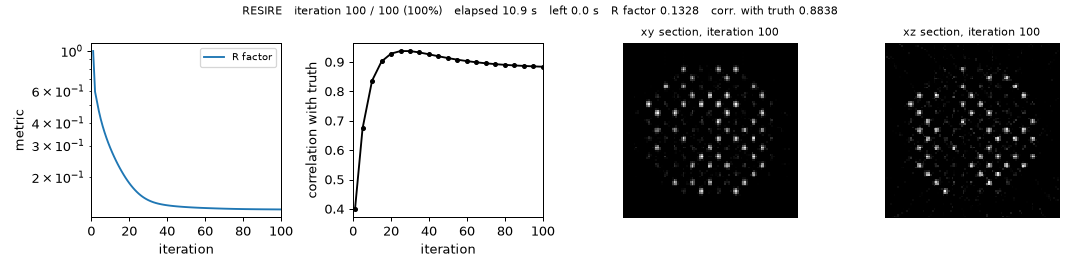

iterations           : 100
final R factor       : 0.13281
best R factor        : 0.13281  (iteration 100)
final loss           : 2.015575e+03
wall clock           : 11.5 s
CPU time (this process): 11.3 s  (1.0 cores busy)


In [4]:
config = rs.ReconstructionConfig(
    num_iterations=100,
    acceleration="fista",
    positivity=True,
    verbose=False)             # 進捗は下の図に表示 / progress is shown in the live figure

truth = shift(particle.volume(), (-0.5, -0.5, -0.5), order=1)   # RESIRE の中心に合わせた正解 / truth on RESIRE's centre
monitor = LiveMonitor(config.num_iterations, every=5, truth=truth, title="RESIRE")
result = rs.reconstruct(b, theta, config, callback=monitor)
resire = result.reconstruction
print(result.summary())

この例では，正解との相関係数は 20〜30 回目あたりで最大になり，その後わずかに下がります．一方，R 因子 は下がり続けます．測定値（ノイズを含む）とのずれが小さいほど正解に近いとは限らない，ということです．実験では正解がわからないので，反復回数はシミュレーションで見当をつけておきます．

In this example the correlation with the ground truth peaks at around 20–30 iterations and then drops slightly, while the R factor keeps falling: fitting the noisy data more closely does not always bring the volume closer to the truth. In experiments, where the truth is unknown, the number of iterations is chosen with the help of simulations like this one.

## 3. 結果を見る / Look at the result

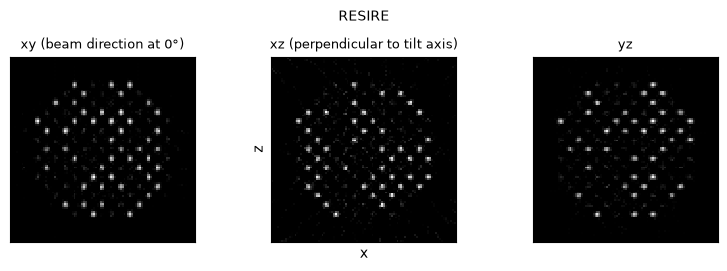

In [5]:
show_orthoslices(resire, "RESIRE"); plt.show()

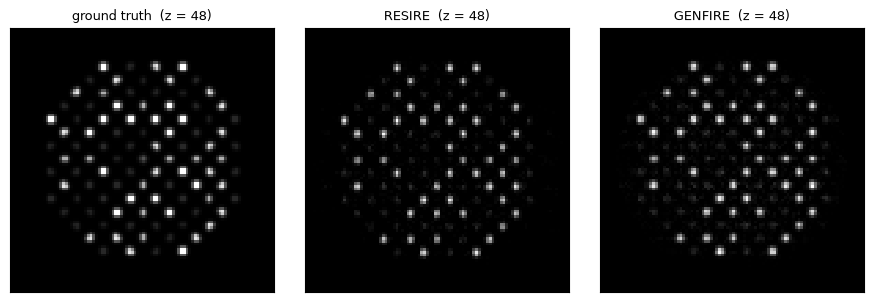

In [6]:
vols = {"ground truth": particle.volume(), "RESIRE": resire}
if (DATA / "genfire.npy").exists():
    vols["GENFIRE"] = np.load(DATA / "genfire.npy")
show_slices(vols, thickness=3); plt.show()

RESIRE の三次元像は，回転中心 `(n−1)/2` を中心とする配列です．05 で原子の座標を比べるときは，この 0.5 ピクセルの違いを考慮します．

The RESIRE volume is centred on `(n−1)/2`. Notebook 05 takes this half-pixel difference into account when comparing atomic positions.

In [7]:
np.save(DATA / "resire.npy", resire)
print("saved: data/resire.npy")

saved: data/resire.npy


### やってみよう / Try it

- `acceleration="none"` にして，同じ R 因子になるまでの反復回数を比べてみましょう．
  Set `acceleration="none"` and compare how many iterations are needed to reach the same R factor.
- 回転中心をずらさずに（`b = projections`）再構成し，05 で原子の位置の精度がどう変わるか見てみましょう．
  Reconstruct without the shift (`b = projections`) and see in 05 how the position precision changes.
- `step_size` を 3 や 4 にすると何が起きるでしょうか． / What happens with `step_size` = 3 or 4?
- 最初のセルで `INPUT = "tilt_series_aligned.npz"` として，02 で位置合わせしたデータを再構成し，05 で理想的なデータと比べてみましょう．
  Set `INPUT = "tilt_series_aligned.npz"` to reconstruct the data aligned in 02, and compare with the ideal data in 05.